# 69 · Tokenize the action and pay the resolution bill: Decision Transformer with 256 → 4 bins

In [1]:
import os, time, importlib.util, numpy as np, torch, matplotlib.pyplot as plt

spec = importlib.util.spec_from_file_location("dtnb", os.path.abspath("dt_lib.py"))
dtnb = importlib.util.module_from_spec(spec); spec.loader.exec_module(dtnb)

In [2]:
data = list(np.load("generated/pendulum_offline.npy", allow_pickle=True))
best = max(e["rew"].sum() for e in data)
cont = dtnb.DecisionTransformer().to(dtnb.device)
cont.load_state_dict(torch.load("generated/dt_pendulum.pt", map_location=dtnb.device)); cont.eval()
base = np.mean([dtnb.rollout_dt(cont, best, seed=3000 + s) for s in range(5)])
print(f"continuous-action DT (MSE head): {base:.0f}")

S07_Sequence_Models/dt_lib.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layer)


continuous-action DT (MSE head): -796


In [3]:
results = {}
for bins in [256, 64, 16, 8, 4, 2]:
    t0 = time.time()
    dt = dtnb.train_dt(data, steps=4000, bins=bins); dt.eval()
    results[bins] = [dtnb.rollout_dt(dt, best, seed=3000 + s) for s in range(5)]
    print(f"{bins:4d} bins (resolution {2 / bins:.3f} N·m-units): achieved {np.mean(results[bins]):7.0f} ± {np.std(results[bins]):4.0f}   ({time.time() - t0:.0f}s)")

 256 bins (resolution 0.008 N·m-units): achieved   -2036 ± 2571   (187s)


S07_Sequence_Models/dt_lib.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layer)


  64 bins (resolution 0.031 N·m-units): achieved    -975 ±  745   (44s)


  16 bins (resolution 0.125 N·m-units): achieved    -695 ±  581   (44s)


   8 bins (resolution 0.250 N·m-units): achieved    -725 ±  611   (25s)


   4 bins (resolution 0.500 N·m-units): achieved    -763 ±  631   (15s)


   2 bins (resolution 1.000 N·m-units): achieved   -1121 ±  533   (15s)


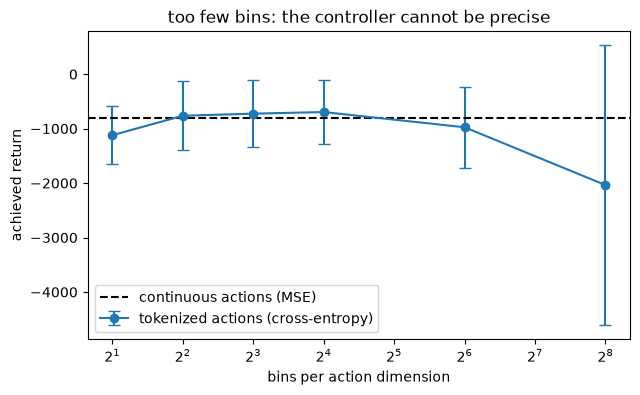

In [4]:
b = sorted(results)
plt.figure(figsize=(7, 4))
plt.errorbar(b, [np.mean(results[k]) for k in b], yerr=[np.std(results[k]) for k in b], marker="o", capsize=4, label="tokenized actions (cross-entropy)")
plt.axhline(base, c="k", ls="--", label="continuous actions (MSE)")
plt.xscale("log", base=2); plt.xlabel("bins per action dimension"); plt.ylabel("achieved return"); plt.legend(); plt.title("too few bins: the controller cannot be precise"); plt.show()